# Netflix Movies & TV Shows – Exploratory Data Analysis

**Student:** Zara Baig
**Dataset:** `netflix_titles.csv`  
**Source:** [Kaggle – Netflix Movies and TV Shows](https://www.kaggle.com/datasets/shivamb/netflix-shows)

**Objective:** Explore Netflix titles to understand content types, release trends, ratings, countries, genres, and movie durations.


## Setup – Import libraries and load the CSV

In [9]:
from google.colab import files

uploaded = files.upload()

Saving netflix_titles.csv to netflix_titles (1).csv


In [10]:
df = pd.read_csv("netflix_titles.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [31]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

df = pd.read_csv("netflix_titles.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


## Step 1 – Understand the data

**Source:** Kaggle – Netflix Movies and TV Shows dataset by Shivam Bansal.  
**One row represents:** One movie or TV show title listed in the dataset.

| Column | Meaning |
|---|---|
| show_id | Unique identifier |
| type | Movie or TV Show |
| title | Title name |
| director | Director name(s) |
| cast | Cast members |
| country | Country/countries associated with the title |
| date_added | Date added to Netflix |
| release_year | Original release year |
| rating | Content maturity rating |
| duration | Movie runtime or number of TV seasons |
| listed_in | Genres/categories |
| description | Short description |


In [12]:
print("Shape (rows, columns):", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data type"))
print("\nFirst five rows:")
display(df.head())
print("\nDescriptive statistics:")
display(df.describe(include="all").T)

Shape (rows, columns): (8807, 12)

Column names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Data types:


,Data type
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,object
release_year,int64
rating,object
duration,object



First five rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Step 2 – Questions to investigate

1. How many titles are Movies and how many are TV Shows?
2. Which release years have the most titles?
3. What are the most common content ratings?
4. Which countries contribute the most titles?
5. Which genres/categories appear most frequently?
6. How does the release-year distribution differ between Movies and TV Shows?
7. How does movie duration vary across common content ratings?
8. How did the number of titles added to Netflix change over time?

These questions use columns available in this dataset. Country and genre fields can contain multiple comma-separated values.

## Step 3 – Clean the data

### 3.1 Missing values – count and graph

,Missing values
director,2634
country,831
cast,825
date_added,10
rating,4
duration,3


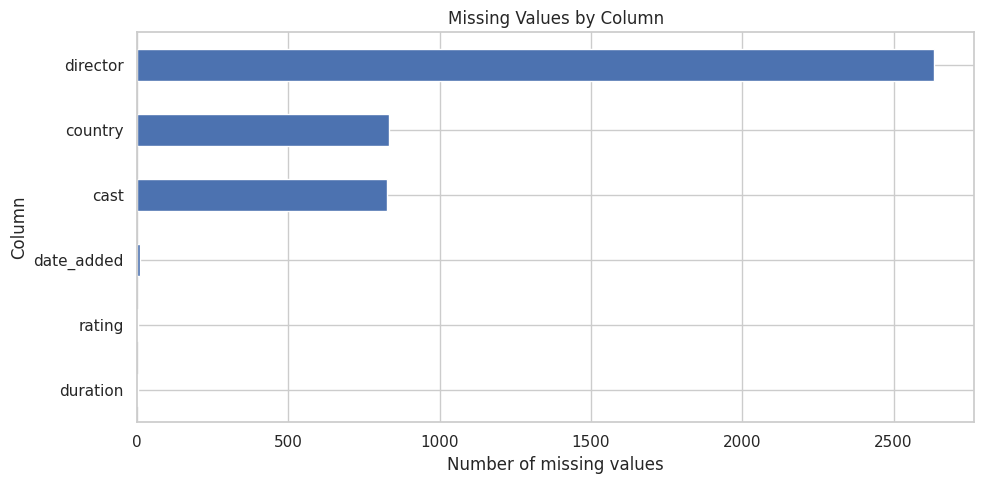

In [13]:
missing = df.isna().sum().sort_values(ascending=False)
display(missing[missing > 0].to_frame("Missing values"))

missing_nonzero = missing[missing > 0]
plt.figure(figsize=(10, 5))
missing_nonzero.sort_values().plot(kind="barh")
plt.title("Missing Values by Column")
plt.xlabel("Number of missing values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [14]:
df_clean = df.copy()

for col in ["director", "cast", "country", "rating", "duration"]:
    df_clean[col] = df_clean[col].fillna("Unknown")

df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"].astype("string").str.strip(),
    format="%B %d, %Y",
    errors="coerce"
)

print("Missing values after cleaning:")
display(df_clean.isna().sum().to_frame("Missing values"))

Missing values after cleaning:


,Missing values
show_id,0
type,0
title,0
director,0
cast,0
country,0
date_added,10
release_year,0
rating,0
duration,0


### 3.2 Repeated rows

In [15]:
duplicate_count = df_clean.duplicated().sum()
print("Repeated rows:", duplicate_count)

df_clean = df_clean.drop_duplicates().copy()
print("Shape after removing repeated rows:", df_clean.shape)

Repeated rows: 0
Shape after removing repeated rows: (8807, 12)


### 3.3 Data types and duration parsing

In [16]:
print("Data types after date conversion:")
display(df_clean.dtypes.to_frame("Data type"))

# Extract movie runtime, for example '90 min'.
df_clean["duration_minutes"] = pd.to_numeric(
    df_clean["duration"].str.extract(r"(\d+)\s*min", expand=False),
    errors="coerce"
)

# Extract TV seasons, for example '2 Seasons'.
df_clean["seasons"] = pd.to_numeric(
    df_clean["duration"].str.extract(r"(\d+)\s*Season", expand=False),
    errors="coerce"
)

display(df_clean[["duration", "duration_minutes", "seasons"]].head(10))

Data types after date conversion:


,Data type
show_id,object
type,object
title,object
director,object
cast,object
country,object
date_added,datetime64[ns]
release_year,int64
rating,object
duration,object


,duration,duration_minutes,seasons
0,90 min,90.0,NaN
1,2 Seasons,NaN,2.0
2,1 Season,NaN,1.0
3,1 Season,NaN,1.0
4,2 Seasons,NaN,2.0
5,1 Season,NaN,1.0
6,91 min,91.0,NaN
7,125 min,125.0,NaN
8,9 Seasons,NaN,9.0
9,104 min,104.0,NaN


### 3.4 Outliers – box plots and IQR rule on two numeric columns


Release year
Q1=2013.00, Q3=2019.00, IQR=6.00
Lower bound=2004.00, Upper bound=2028.00
Outlier count: 719


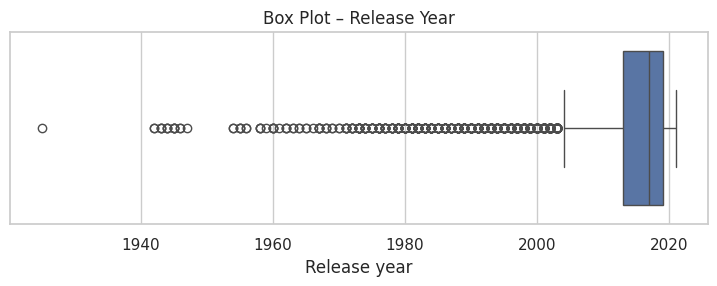


Movie duration (minutes)
Q1=87.00, Q3=114.00, IQR=27.00
Lower bound=46.50, Upper bound=154.50
Outlier count: 450


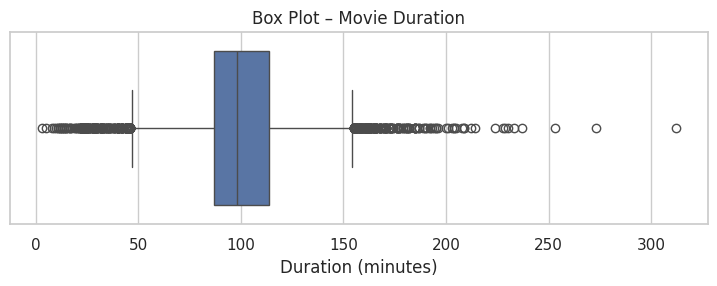

In [17]:
def iqr_report(series, column_name):
    values = series.dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = values[(values < lower) | (values > upper)]
    print(f"\n{column_name}")
    print(f"Q1={q1:.2f}, Q3={q3:.2f}, IQR={iqr:.2f}")
    print(f"Lower bound={lower:.2f}, Upper bound={upper:.2f}")
    print("Outlier count:", len(outliers))
    return outliers

release_outliers = iqr_report(df_clean["release_year"], "Release year")
plt.figure(figsize=(9, 2.5))
sns.boxplot(x=df_clean["release_year"])
plt.title("Box Plot – Release Year")
plt.xlabel("Release year")
plt.show()

duration_outliers = iqr_report(df_clean["duration_minutes"], "Movie duration (minutes)")
plt.figure(figsize=(9, 2.5))
sns.boxplot(x=df_clean["duration_minutes"])
plt.title("Box Plot – Movie Duration")
plt.xlabel("Duration (minutes)")
plt.show()

## Step 4 – Univariate analysis

### 4.1 Numeric columns

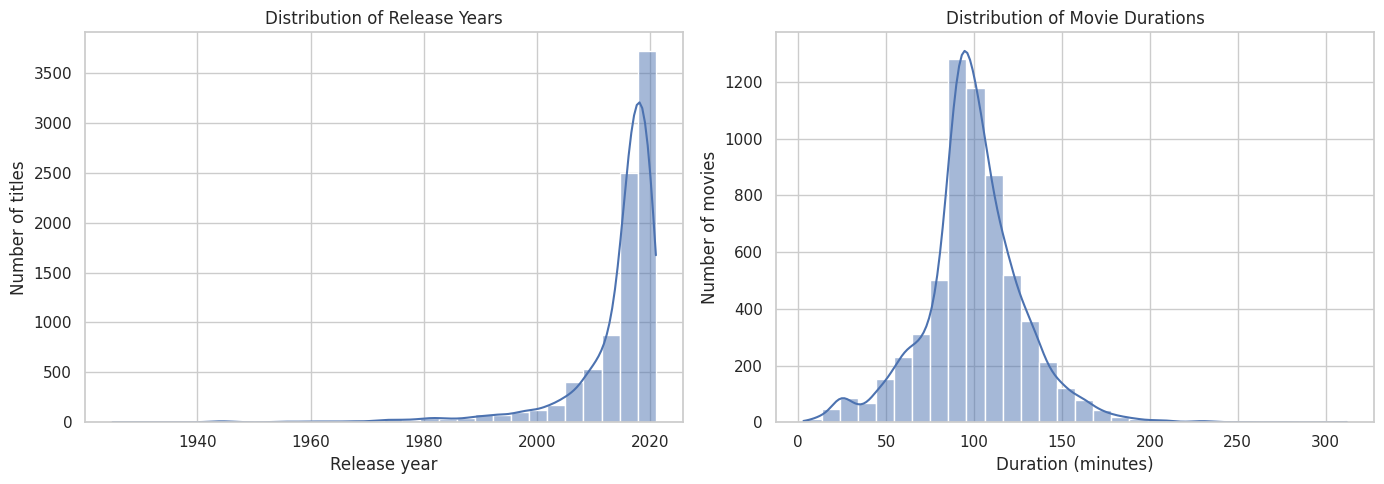

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_clean["release_year"], bins=30, ax=axes[0], kde=True)
axes[0].set_title("Distribution of Release Years")
axes[0].set_xlabel("Release year")
axes[0].set_ylabel("Number of titles")

sns.histplot(df_clean["duration_minutes"].dropna(), bins=30, ax=axes[1], kde=True)
axes[1].set_title("Distribution of Movie Durations")
axes[1].set_xlabel("Duration (minutes)")
axes[1].set_ylabel("Number of movies")
plt.tight_layout()
plt.show()

### 4.2 Categorical columns

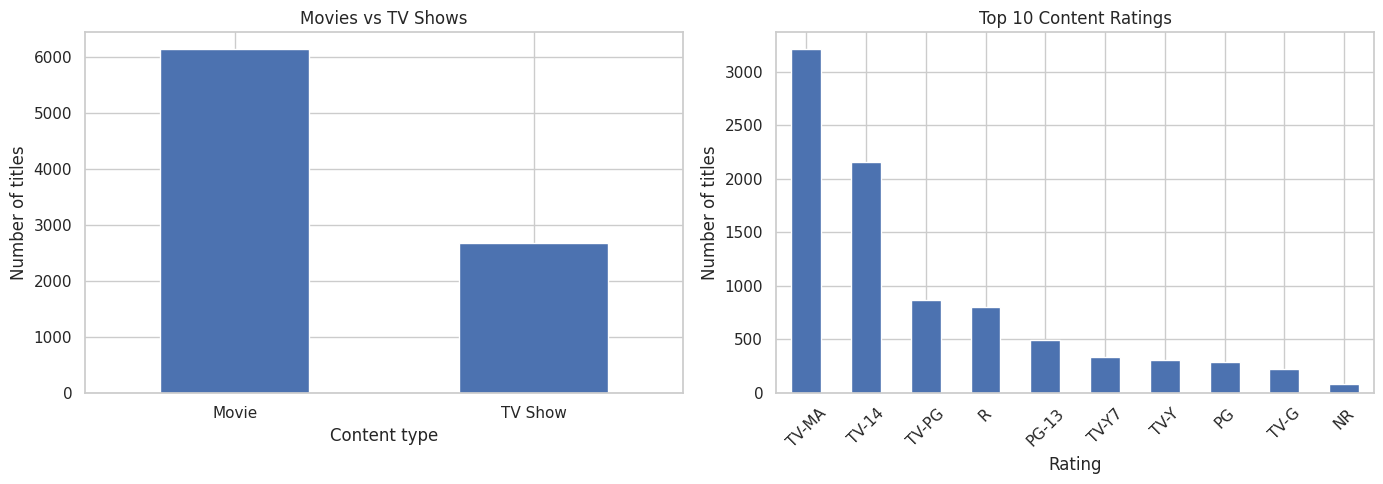

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df_clean["type"].value_counts().plot(kind="bar", ax=axes[0])
axes[0].set_title("Movies vs TV Shows")
axes[0].set_xlabel("Content type")
axes[0].set_ylabel("Number of titles")
axes[0].tick_params(axis="x", rotation=0)

df_clean["rating"].value_counts().head(10).plot(kind="bar", ax=axes[1])
axes[1].set_title("Top 10 Content Ratings")
axes[1].set_xlabel("Rating")
axes[1].set_ylabel("Number of titles")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## Step 5 – Bivariate analysis

### 5.1 Scatter plot – release year vs movie duration

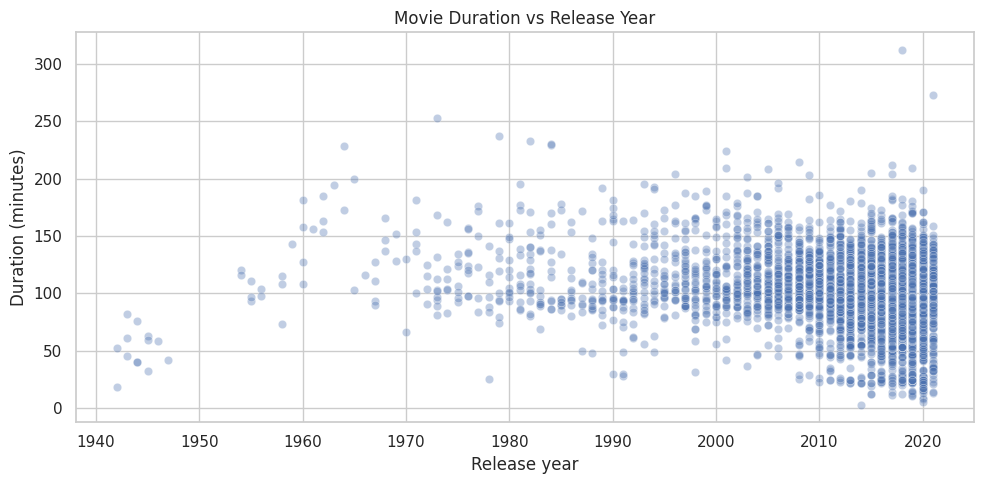

In [20]:
movies = df_clean[df_clean["type"] == "Movie"].dropna(subset=["duration_minutes"])
plt.figure(figsize=(10, 5))
sns.scatterplot(data=movies, x="release_year", y="duration_minutes", alpha=0.35)
plt.title("Movie Duration vs Release Year")
plt.xlabel("Release year")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()

### 5.2 Correlation heatmap

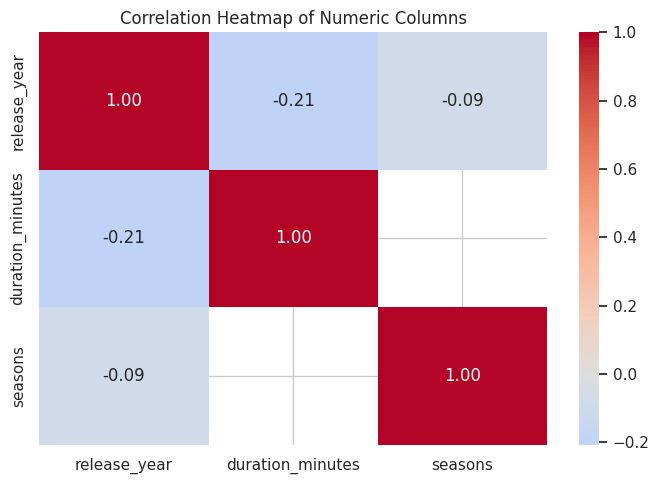

In [21]:
corr = df_clean[["release_year", "duration_minutes", "seasons"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap of Numeric Columns")
plt.tight_layout()
plt.show()

### 5.3 Compare a numeric column across categories

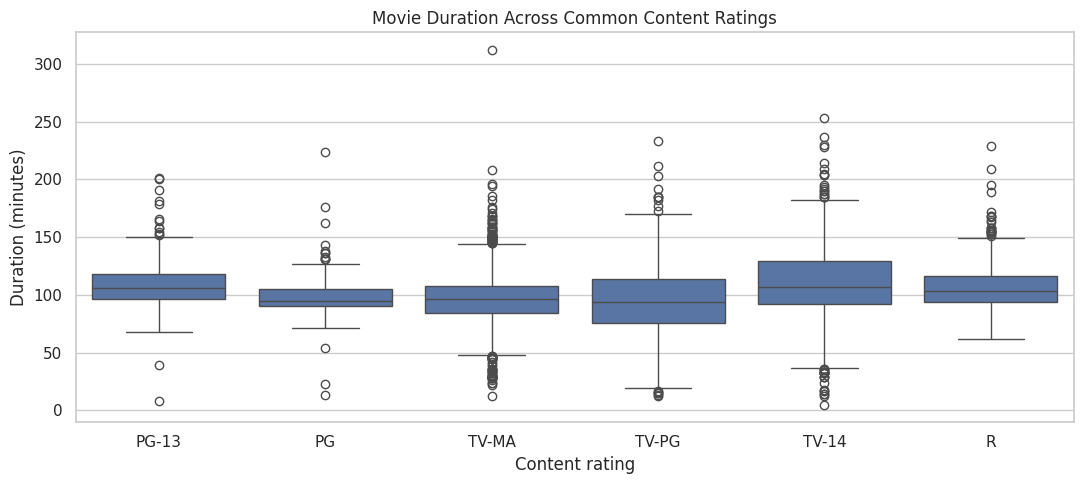

In [22]:
top_ratings = movies["rating"].value_counts().head(6).index
rating_duration = movies[movies["rating"].isin(top_ratings)]

plt.figure(figsize=(11, 5))
sns.boxplot(data=rating_duration, x="rating", y="duration_minutes")
plt.title("Movie Duration Across Common Content Ratings")
plt.xlabel("Content rating")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()

## Step 6 – Answer all eight questions

### Q1. How many titles are Movies and how many are TV Shows?

,Number of titles
type,
Movie,6131
TV Show,2676


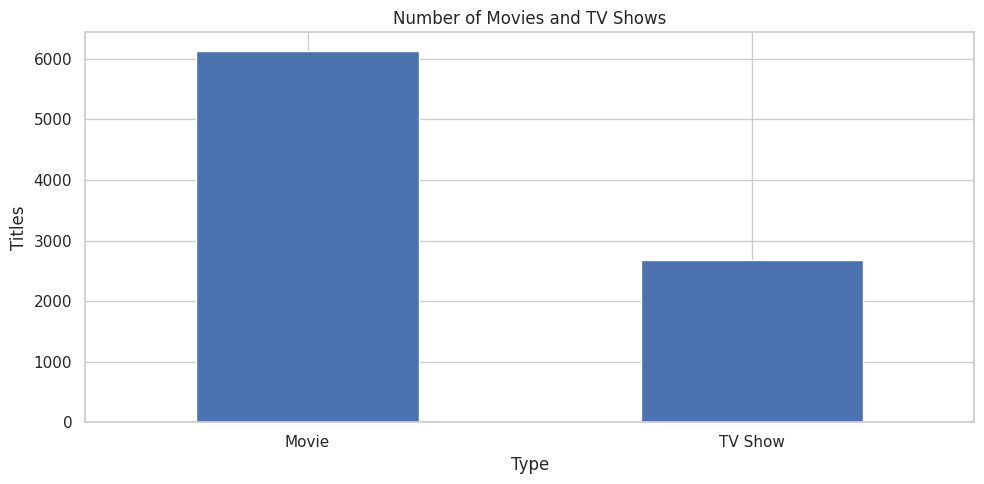

In [23]:
type_counts = df_clean["type"].value_counts()
display(type_counts.to_frame("Number of titles"))
type_counts.plot(kind="bar", title="Number of Movies and TV Shows",
                 xlabel="Type", ylabel="Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Q2. Which release years have the most titles?

,Titles
release_year,
2018,1147
2017,1032
2019,1030
2020,953
2016,902
2021,592
2015,560
2014,352
2013,288


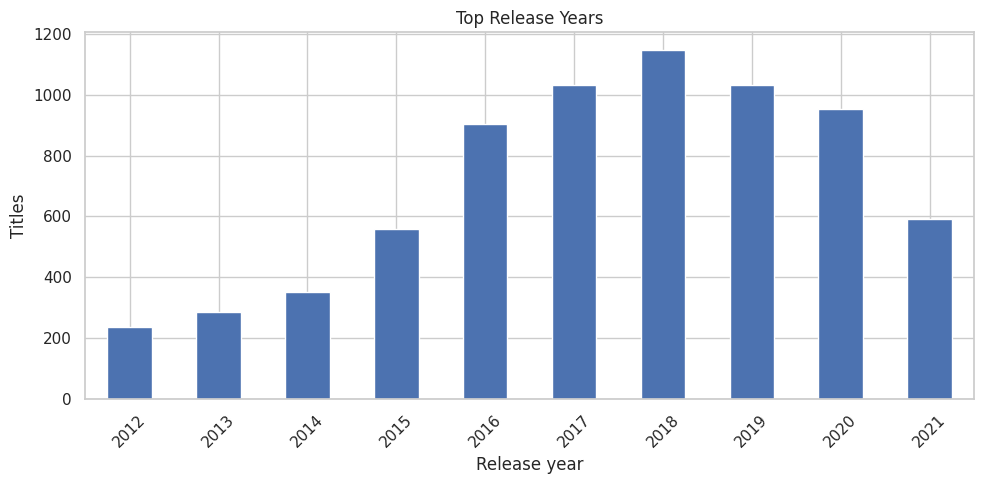

In [24]:
display(df_clean["release_year"].value_counts().head(10).to_frame("Titles"))
df_clean["release_year"].value_counts().head(10).sort_index().plot(
    kind="bar", figsize=(10, 5), title="Top Release Years",
    xlabel="Release year", ylabel="Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Q3. What are the most common content ratings?

,Titles
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


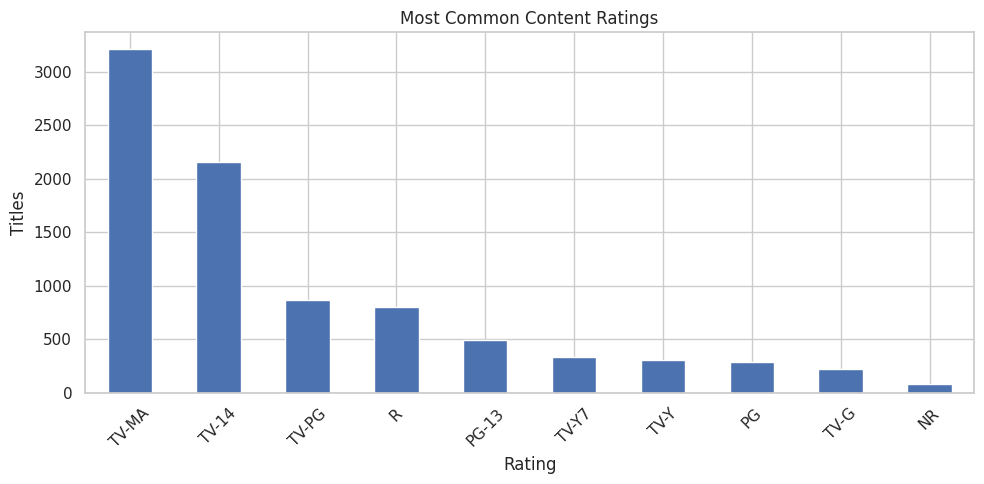

In [25]:
rating_counts = df_clean["rating"].value_counts().head(10)
display(rating_counts.to_frame("Titles"))
rating_counts.plot(kind="bar", figsize=(10, 5), title="Most Common Content Ratings",
                   xlabel="Rating", ylabel="Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Q4. Which countries contribute the most titles?

,Titles
country,
United States,3689
India,1046
United Kingdom,804
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226


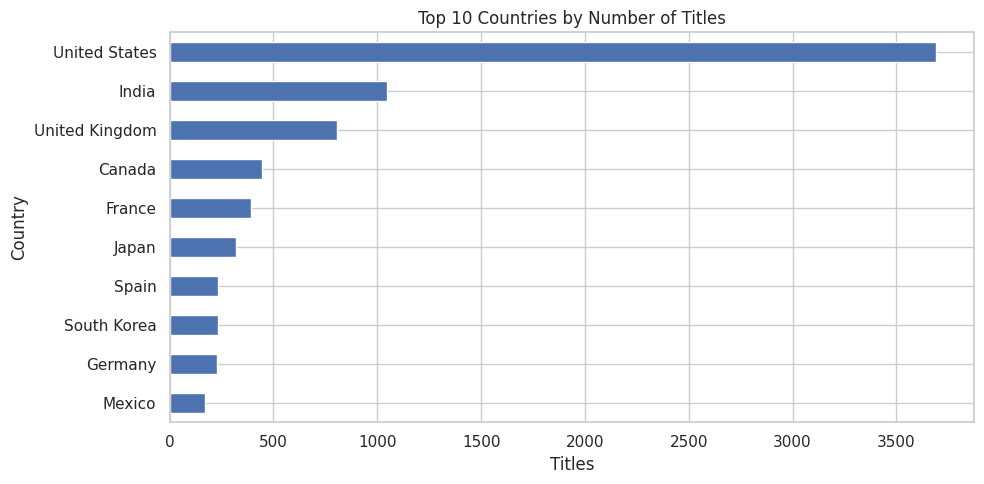

In [26]:
country_counts = (df_clean.loc[df_clean["country"] != "Unknown", "country"]
                 .str.split(", ").explode().value_counts().head(10))
display(country_counts.to_frame("Titles"))
country_counts.sort_values().plot(kind="barh", figsize=(10, 5),
    title="Top 10 Countries by Number of Titles", xlabel="Titles", ylabel="Country")
plt.tight_layout()
plt.show()

### Q5. Which genres/categories appear most frequently?

,Titles
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


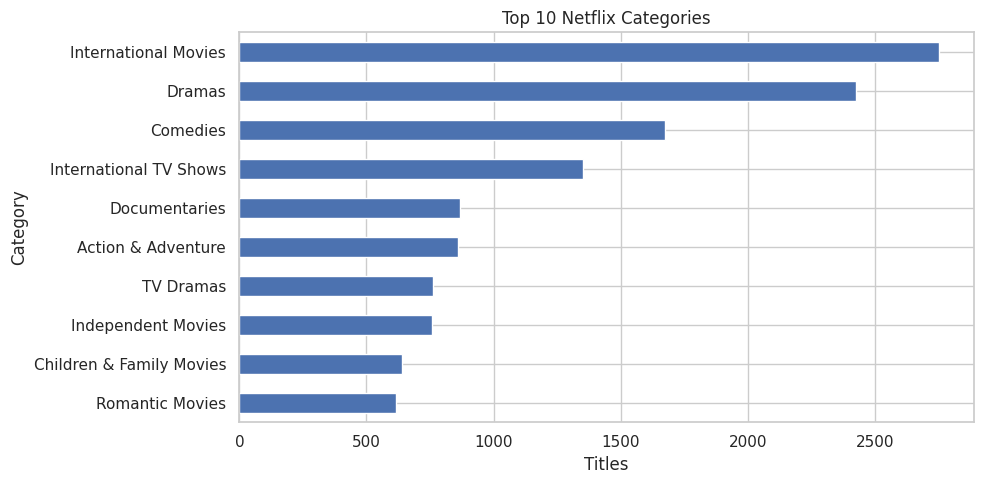

In [27]:
genre_counts = df_clean["listed_in"].str.split(", ").explode().value_counts().head(10)
display(genre_counts.to_frame("Titles"))
genre_counts.sort_values().plot(kind="barh", figsize=(10, 5),
    title="Top 10 Netflix Categories", xlabel="Titles", ylabel="Category")
plt.tight_layout()
plt.show()

### Q6. How does the release-year distribution differ between Movies and TV Shows?

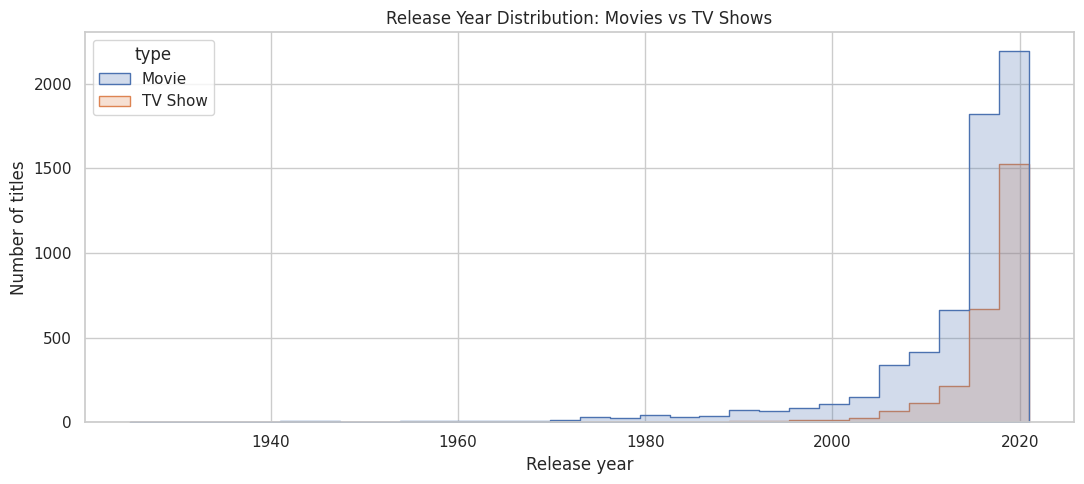

In [28]:
plt.figure(figsize=(11, 5))
sns.histplot(data=df_clean, x="release_year", hue="type", bins=30,
             element="step", stat="count", common_norm=False)
plt.title("Release Year Distribution: Movies vs TV Shows")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.tight_layout()
plt.show()

### Q7. How does movie duration vary across common content ratings?

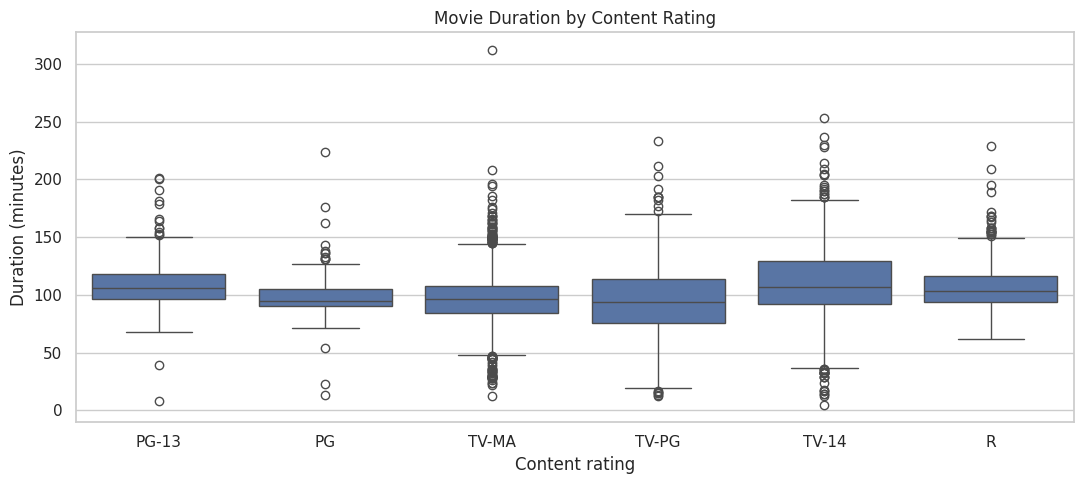

In [29]:
plt.figure(figsize=(11, 5))
sns.boxplot(data=rating_duration, x="rating", y="duration_minutes")
plt.title("Movie Duration by Content Rating")
plt.xlabel("Content rating")
plt.ylabel("Duration (minutes)")
plt.tight_layout()
plt.show()

### Q8. How did the number of titles added to Netflix change over time?

,Titles added
added_year,
2008,2
2009,2
2010,1
2011,13
2012,3
2013,11
2014,24
2015,82
2016,429


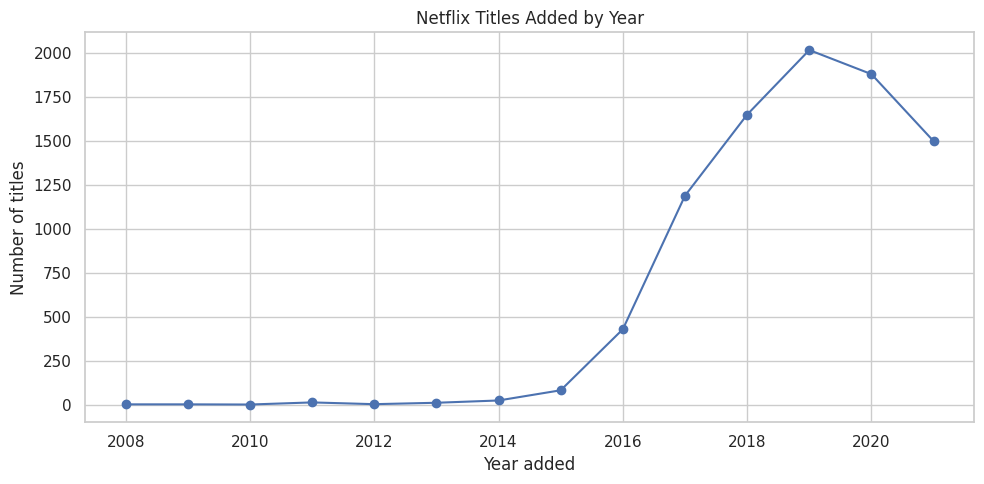

In [30]:
added_by_year = (df_clean.dropna(subset=["date_added"])
                 .assign(added_year=lambda x: x["date_added"].dt.year)
                 .groupby("added_year").size())
display(added_by_year.to_frame("Titles added"))
added_by_year.plot(kind="line", marker="o", figsize=(10, 5),
    title="Netflix Titles Added by Year", xlabel="Year added", ylabel="Number of titles")
plt.tight_layout()
plt.show()

# Step 7 – Conclusion

## Three Main Findings

**Finding 1: Movies vs TV Shows**

The analysis shows that Netflix has 6,131 Movies and 2,676 TV Shows. Movies represent the majority of the content, showing that the platform has more movies than TV shows in this dataset.

**Finding 2: Top Countries and Genres**

The United States contributes the highest number of titles with 3,689 entries, followed by India with 1,046 entries. International Movies is the most common category, with 2,752 titles, followed by Dramas with 2,427 titles.

**Finding 3: Movie Duration**

The average movie duration is approximately 100 minutes, while the median duration is 98 minutes. This shows that most movies have a runtime around 1 hour and 40 minutes.

## One Actionable Suggestion

Netflix should use country-wise and genre-wise viewing trends to plan its future content. It should consider investing in popular genres such as International Movies and Dramas while providing more diverse content for different audiences.

## Final Conclusion

This exploratory data analysis helped us understand Netflix's content distribution, popular genres, leading countries, content ratings, and movie durations. Data cleaning and visualization made it easier to identify patterns and understand the dataset.

The project demonstrates how data analysis can help businesses make better content-planning decisions.